# Inteligentna analiza podatkov – Diagnostika raka dojk

**Avtor:** Nađa Tomović  
**Predmet:** Inteligentni sistemi in strojno učenje  
**Datum:** januar 2026.


## Uvod

V okviru projekta izvajamo inteligentno analizo podatkov s področja bioinformatike.
Uporabljeni podatki vsebujejo morfološke značilnosti celičnih jeder, pridobljene iz
mikroskopskih slik biopsije dojk. Cilj analize je ugotoviti, ali je mogoče na podlagi
teh značilnosti razlikovati med benignimi in malignimi tumorji.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
#Nalaganje datoteke na katero vrsimo potrebne analize

df = pd.read_csv("data/data.csv", sep=",", decimal=".")

df.head()


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [3]:
print("Število vrstic in stolpcev:", df.shape)


Število vrstic in stolpcev: (569, 33)


In [4]:
#Izpišemo podatkovne tipe posameznih stolpcev in preverimo, ali gre za
#numerične ali kategorične podatke.

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [5]:
#Stolpec `id` predstavlja zgolj identifikator vzorca in ne vsebuje diagnostičnih informacij.
#Stolpec `Unnamed: 32` je prazen in je nastal kot artefakt pri izvozu podatkov.
#Oba stolpca odstranimo iz nadaljnje analize.

df = df.drop(columns=["id", "Unnamed: 32"])
df.head()


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [6]:
#Preverimo, ali datoteka vsebuje manjkajoče vrednosti.

df.isna().sum()

,0
diagnosis,0
radius_mean,0
texture_mean,0
perimeter_mean,0
area_mean,0
smoothness_mean,0
compactness_mean,0
concavity_mean,0
concave points_mean,0
symmetry_mean,0


Potvrdili smo da naš dataset nima manjkajočih podatkov in lahko nastavimo naprej z analizo istega


Ciljna spremenljivka `diagnosis` je kategoričnega tipa (B – benigni, M – maligni tumor).
Za potrebe binarne klasifikacije jo pretvorimo v numerično obliko:
- **0** predstavlja **benigni tumor**
- **1** predstavlja **maligni tumor**

In [7]:
#Uporabimo rocno mapiranje
df["diagnosis"] = df["diagnosis"].map({"B": 0, "M": 1})
df["diagnosis"].value_counts()

,count
diagnosis,
0,357
1,212


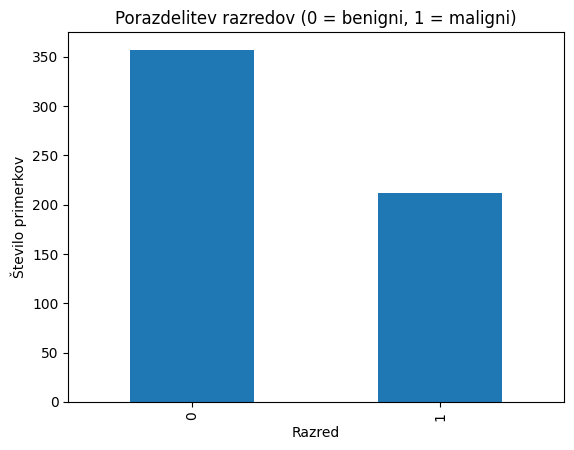

In [8]:
#Stolpcni diagram razredov
df["diagnosis"].value_counts().plot(kind="bar")
plt.title("Porazdelitev razredov (0 = benigni, 1 = maligni)")
plt.xlabel("Razred")
plt.ylabel("Število primerkov")
plt.show()

## 2. Vizualizacija podatkov

Za boljše razumevanje razlik med benignimi in malignimi tumorji izvedemo smiselno
vizualizacijo podatkov. Primerjamo povprečne vrednosti izbranih morfoloških značilnosti
glede na diagnozo.


<Figure size 640x480 with 0 Axes>

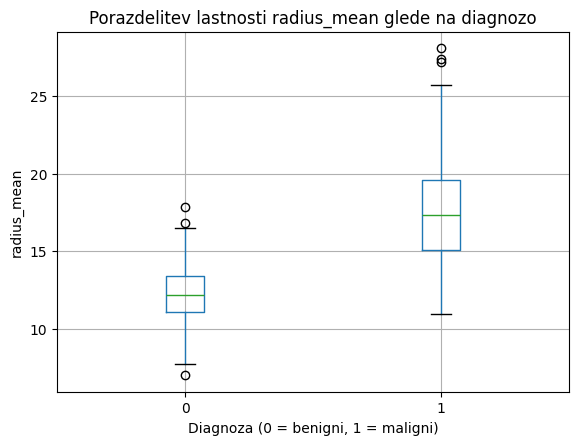

<Figure size 640x480 with 0 Axes>

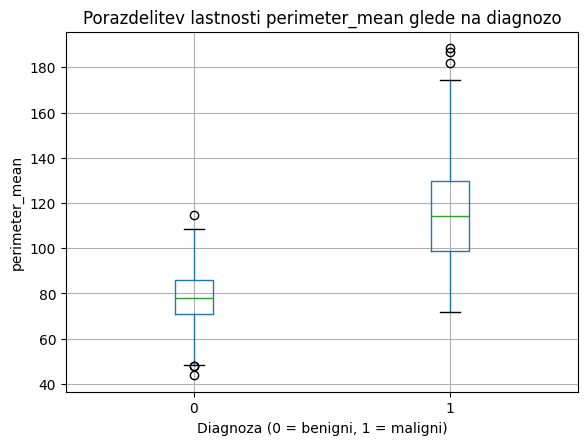

<Figure size 640x480 with 0 Axes>

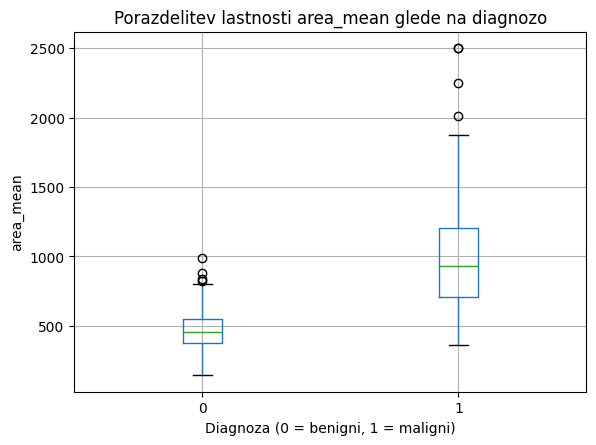

<Figure size 640x480 with 0 Axes>

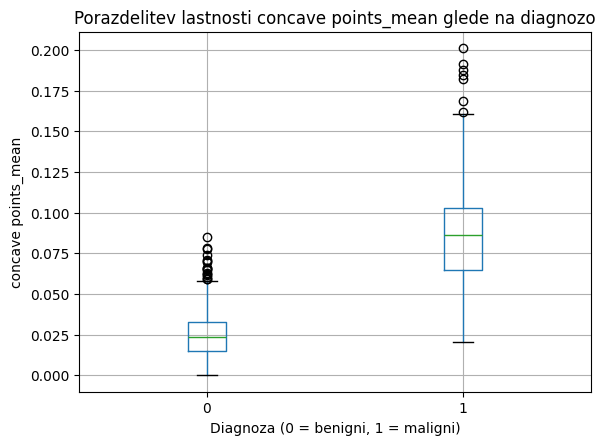

In [9]:
features = [
    "radius_mean",
    "perimeter_mean",
    "area_mean",
    "concave points_mean"
]

for col in features:
    plt.figure()
    df.boxplot(column=col, by="diagnosis")
    plt.title(f"Porazdelitev lastnosti {col} glede na diagnozo")
    plt.suptitle("")
    plt.xlabel("Diagnoza (0 = benigni, 1 = maligni)")
    plt.ylabel(col)
    plt.show()


`radius_mean` predstavlja povprečno razdaljo od središča celičnega jedra do njegovega roba.
Večje vrednosti pomenijo večja celična jedra, kar je pogosto povezano z malignimi tumorji,
saj so rakave celice običajno večje in nepravilne oblike.

`perimeter_mean` predstavlja povprečno dolžino oboda celičnega jedra.
Ta lastnost je tesno povezana z velikostjo in obliko jedra – večje in bolj nepravilne
celice imajo daljši obod, kar je značilno za maligne spremembe.

`area_mean` predstavlja povprečno površino celičnega jedra.
Maligni tumorji pogosto vsebujejo večja jedra z večjo površino, kar se odraža
v višjih vrednostih tega atributa.

`concave points_mean` predstavlja povprečno število konkavnih točk na robu celičnega jedra.
Konkavne točke nakazujejo nepravilnosti na robu celice, ki so pogostejše pri malignih tumorjih,
zato je ta lastnost zelo pomembna za razlikovanje med benignimi in malignimi primeri.


Na prikazanih box-plot diagramih so prikazane porazdelitve izbranih morfoloških značilnosti glede na diagnozo (0 – benigni, 1 – maligni tumor).

Pri vseh opazovanih lastnostih (radius_mean, perimeter_mean, area_mean in concave_points_mean) je opazna jasna razlika med benignimi in malignimi tumorji. Maligni tumorji imajo v povprečju višje mediane in večji razpon vrednosti, kar kaže na večjo velikost in bolj nepravilno obliko tumorskih struktur.

radius_mean, perimeter_mean in area_mean:
Pri malignih primerih so vrednosti izrazito višje, kar odraža večjo velikost tumorjev. Razpon vrednosti je širši, kar kaže na večjo variabilnost malignih tumorjev.

concave_points_mean:
Ta lastnost kaže najbolj izrazito ločitev med razredoma, saj so vrednosti pri malignih tumorjih bistveno višje. To potrjuje, da je stopnja konkavnosti pomemben indikator malignosti.

Prisotnost delnega prekrivanja razponov pri posameznih lastnostih nakazuje, da ena sama značilnost ne zadostuje za zanesljivo diagnozo, vendar kombinacija več lastnosti omogoča dobro ločljivost razredov.

Na podlagi teh vizualizacij lahko sklepamo, da so izbrane značilnosti informativne in primerne za uporabo v nadaljnjih modelih strojnega učenja, zlasti pri nalogah binarne klasifikacije.

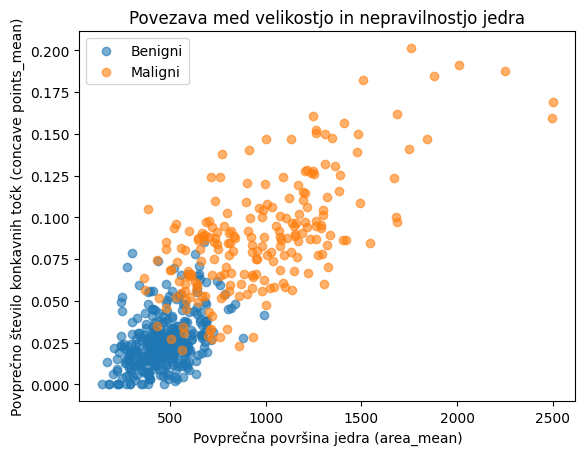

In [10]:
#Ali vecji tumori imajo nepravilnije ivice?
plt.figure()
for label, color in zip([0, 1], ["blue", "orange"]):
    subset = df[df["diagnosis"] == label]
    plt.scatter(
        subset["area_mean"],
        subset["concave points_mean"],
        label=f"{'Benigni' if label == 0 else 'Maligni'}",
        alpha=0.6
    )

plt.xlabel("Povprečna površina jedra (area_mean)")
plt.ylabel("Povprečno število konkavnih točk (concave points_mean)")
plt.title("Povezava med velikostjo in nepravilnostjo jedra")
plt.legend()
plt.show()


Vidimo, da se benigni primerki večinoma nahajajo v spodnjem levem delu grafa, kar pomeni manjšo velikost jedra in nižjo stopnjo nepravilnosti roba. Nasprotno pa se maligni primerki pojavljajo pri večjih vrednostih obeh lastnosti, kar kaže na to, da so maligni tumorji praviloma večji in imajo izrazitejše nepravilnosti robov. Opazna je tudi delna ločitev razredov, kar potrjuje, da kombinacija teh dveh lastnosti dobro prispeva k razlikovanju med benignimi in malignimi primeri.

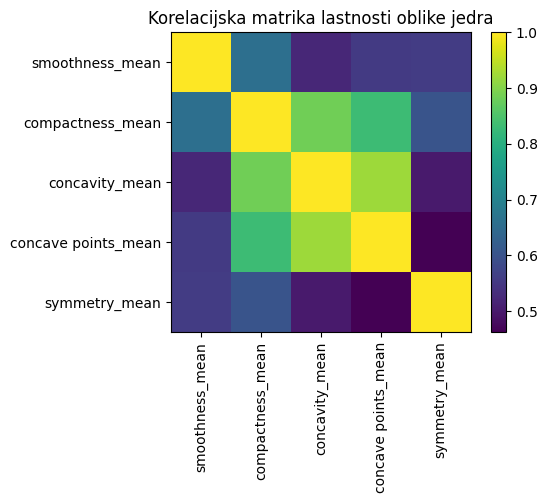

In [11]:
#Korelacijska matrika

shape_features = [
    "smoothness_mean",
    "compactness_mean",
    "concavity_mean",
    "concave points_mean",
    "symmetry_mean"
]

corr_shape = df[shape_features].corr()

plt.figure(figsize=(6, 5))
plt.imshow(corr_shape)
plt.colorbar()

plt.xticks(range(len(shape_features)), shape_features, rotation=90)
plt.yticks(range(len(shape_features)), shape_features)

plt.title("Korelacijska matrika lastnosti oblike jedra")
plt.tight_layout()
plt.show()




`smoothness_mean` predstavlja povprečno gladkost roba celičnega jedra.
Višje vrednosti pomenijo bolj enakomeren rob, medtem ko nižje vrednosti
nakazujejo več nepravilnosti, kar je pogosto značilno za maligne tumorje.

`compactness_mean` meri, kako zgoščeno oziroma kompaktno je celično jedro.
Izračuna se na podlagi razmerja med obodom in površino jedra.
Višje vrednosti pomenijo bolj nepravilno obliko, kar je lahko znak malignih sprememb.

`concavity_mean` predstavlja povprečno stopnjo vdolbin (konkavnosti) na robu celičnega jedra.
Izrazite konkavnosti so značilne za nepravilne oblike, ki se pogosteje pojavljajo pri malignih tumorjih.

`concave points_mean` predstavlja povprečno število konkavnih točk na robu celičnega jedra.
Večje število konkavnih točk pomeni večjo nepravilnost roba, zaradi česar je ta lastnost
ena najpomembnejših za razlikovanje med benignimi in malignimi primeri.

`symmetry_mean` meri povprečno simetričnost celičnega jedra.
Benigna jedra so običajno bolj simetrična, medtem ko so maligna jedra pogosto
asimetrična, kar se odraža v nižji stopnji simetrije.


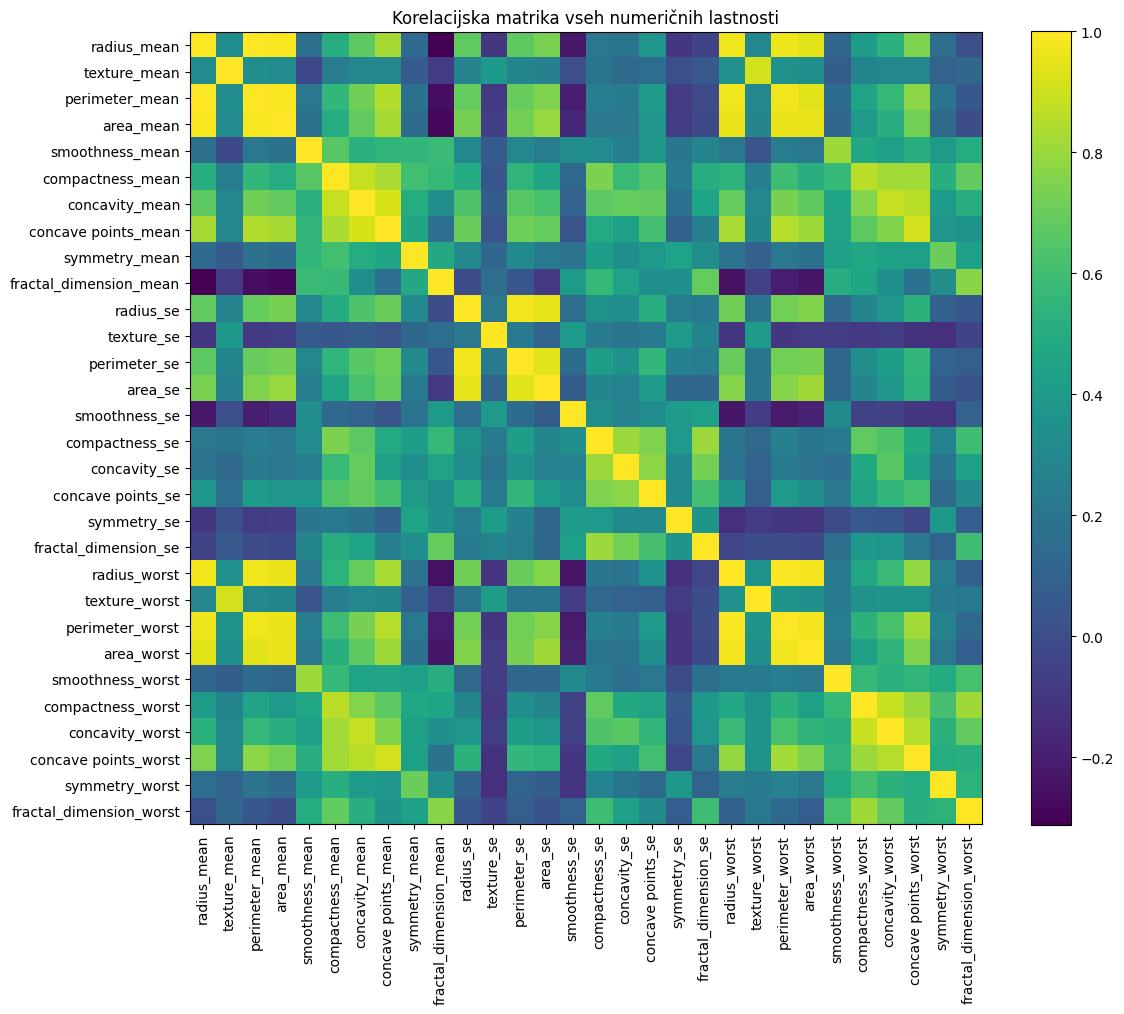

In [12]:
numeric_features = df.drop(columns=["diagnosis"]).select_dtypes(include=[np.number]).columns
corr_all = df[numeric_features].corr()

plt.figure(figsize=(12, 10))
plt.imshow(corr_all)
plt.colorbar()

plt.xticks(range(len(numeric_features)), numeric_features, rotation=90)
plt.yticks(range(len(numeric_features)), numeric_features)

plt.title("Korelacijska matrika vseh numeričnih lastnosti")
plt.tight_layout()
plt.show()


Opazimo močno pozitivno korelacijo med lastnostmi compactness_mean, concavity_mean in concave_points_mean, kar je pričakovano, saj vse opisujejo stopnjo nepravilnosti roba jedra. Lastnost smoothness_mean kaže šibkejšo korelacijo z ostalimi, medtem ko je symmetry_mean relativno neodvisna. Rezultati kažejo, da nekatere lastnosti nosijo podobne informacije, kar je pomembno upoštevati pri nadaljnjem modeliranju, saj lahko visoka korelacija vpliva na izbiro in interpretacijo modelov.

In [13]:
profile_features = [
    "radius_mean",
    "area_mean",
    "compactness_mean",
    "concavity_mean",
    "concave points_mean",
    "symmetry_mean"
]


In [14]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaled_profile = scaler.fit_transform(df[profile_features])

df_profile = pd.DataFrame(
    scaled_profile,
    columns=profile_features
)
df_profile["diagnosis"] = df["diagnosis"]


In [15]:
profile_means = df_profile.groupby("diagnosis").mean()
profile_means.index = ["Benigni", "Maligni"]
profile_means


,radius_mean,area_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean
Benigni,-0.562566,-0.546349,-0.459694,-0.536621,-0.598465,-0.254685
Maligni,0.947340,0.920031,0.774107,0.903649,1.007793,0.428880


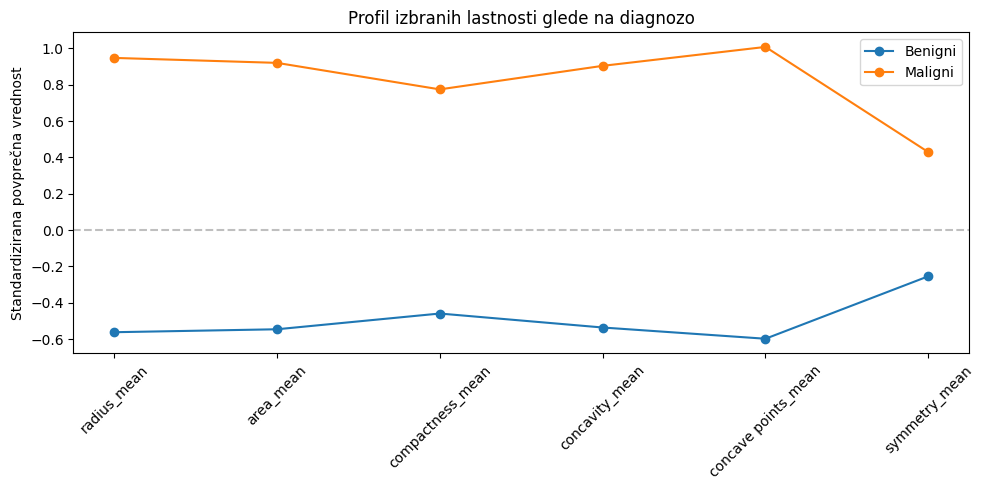

In [16]:
plt.figure(figsize=(10, 5))

for diag in profile_means.index:
    plt.plot(
        profile_means.columns,
        profile_means.loc[diag],
        marker="o",
        label=diag
    )

plt.axhline(0, color="gray", linestyle="--", alpha=0.5)
plt.xticks(rotation=45)
plt.ylabel("Standardizirana povprečna vrednost")
plt.title("Profil izbranih lastnosti glede na diagnozo")
plt.legend()
plt.tight_layout()
plt.show()


Graf standardiziranih povprečnih vrednosti kaže, da se benigni in maligni primerki razlikujejo po doslednem vzorcu skozi več lastnosti. Maligni primerki dosegajo višje vrednosti pri lastnostih, povezanih z velikostjo in nepravilnostjo jedra, medtem ko so vrednosti pri benignih primerkih pod povprečjem. To kaže, da so razlike sistematične in ne temeljijo zgolj na posamezni lastnosti.

## 3. Gručenje – priprava podatkov

Pred gručenjem uporabimo samo številske podatke.
Ciljne spremenljivke `diagnosis` pri gručenju ne uporabljamo, saj želimo odkriti naravne skupine v podatkih brez nadzora.
Ker imajo lastnosti različne skale, podatke standardiziramo.


In [17]:
from sklearn.preprocessing import StandardScaler

# 1) odstranimo cilj (diagnosis) in uporabimo samo numericne lastnosti
X = df.drop(columns=["diagnosis"]).copy()

# vse ostale kolone so nam stevilske ampak bomo dodali selekcijo
X = X.select_dtypes(include=[np.number])

# 2) standardizacija
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X.shape


(569, 30)

### Hierarhično gručenje (dendrogram)

Za približen vpogled v strukturo podatkov uporabimo hierarhično gručenje in izrišemo dendrogram.
Dendrogram prikažemo z maksimalno delitvijo na 4 nivoje, da ostane pregleden.


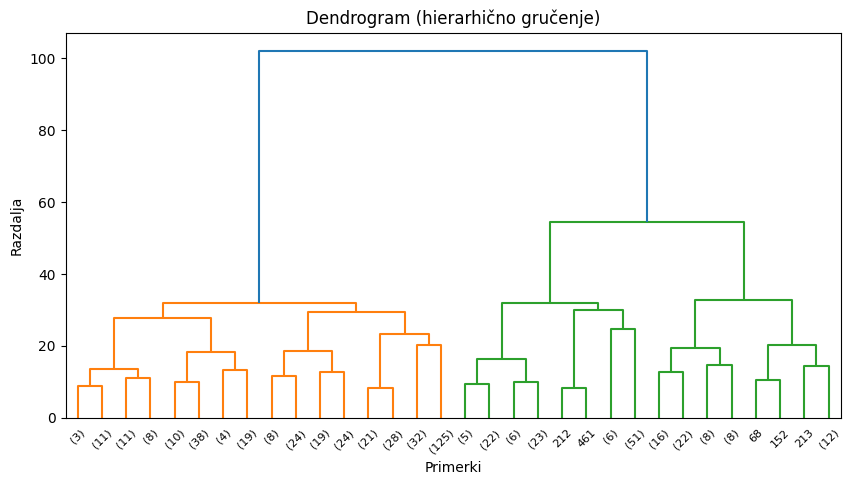

In [18]:
from scipy.cluster.hierarchy import linkage, dendrogram

Z = linkage(X_scaled, method="ward")

plt.figure(figsize=(10, 5))
dendrogram(Z, truncate_mode="level", p=4)
plt.title("Dendrogram (hierarhično gručenje)")
plt.xlabel("Primerki")
plt.ylabel("Razdalja")
plt.show()


Na prikazanem dendrogramu vidimo rezultat hierarhičnega gručenja podatkov.
Posamezni listi na dnu drevesa predstavljajo posamezne primerke (vzorce) iz podatkovne zbirke,
medtem ko višina povezav (razdalja) kaže, kako podobni so si primerki ali skupine primerkov.

Opazimo, da se podatki že pri relativno nizkih razdaljah združujejo v manjše skupine,
na višjem nivoju pa se jasno izoblikujeta dve večji gruči.
To nakazuje, da je delitev podatkov v dve gruči smiselna, kar je skladno z nadaljnjo
uporabo algoritma K-means z dvema gručama.


In [19]:
#K-means za k=2

from sklearn.cluster import KMeans

kmeans_2 = KMeans(n_clusters=2, random_state=42)
labels_2 = kmeans_2.fit_predict(X_scaled)

# Število instanc v vsaki gruči
unique, counts = np.unique(labels_2, return_counts=True)
dict(zip(unique, counts))


{np.int32(0): np.int64(188), np.int32(1): np.int64(381)}

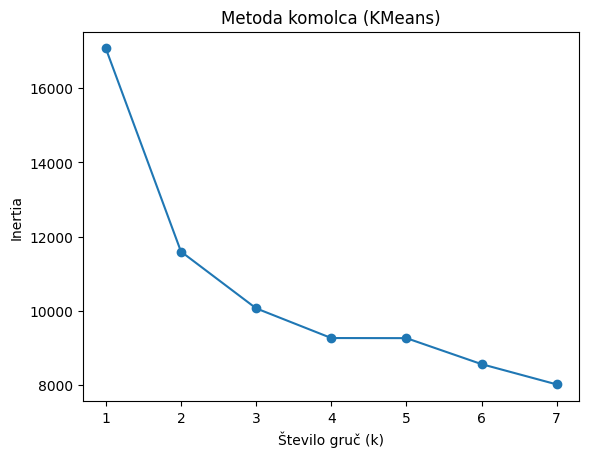

In [20]:
#Analiza optimalnega števila gruč (metoda komolca)
inertias = []
k_values = range(1, 8)

for k in k_values:
    km = KMeans(n_clusters=k, random_state=42)
    km.fit(X_scaled)
    inertias.append(km.inertia_)

plt.figure()
plt.plot(list(k_values), inertias, marker="o")
plt.title("Metoda komolca (KMeans)")
plt.xlabel("Število gruč (k)")
plt.ylabel("Inertia")
plt.show()


Na grafu vidimo da je najboljsa izbira k=2 ali k=3. Mi izbiramo k=2 ker tu opazimo veliki padec vrednosti

In [21]:
k_opt = 2

kmeans = KMeans(n_clusters=k_opt, random_state=42)
labels_opt = kmeans.fit_predict(X_scaled)

df["cluster"] = labels_opt
df["cluster"].value_counts()

,count
cluster,
1,381
0,188


## PCA transformacija (2 komponenti) in prikaz gruč

S PCA transformacijo zmanjšamo dimenzionalnost na 2 komponenti in rezultate prikažemo v grafu raztrosa.
Primerki so obarvani glede na gruče, ki jih določi K-means (optimalni k).


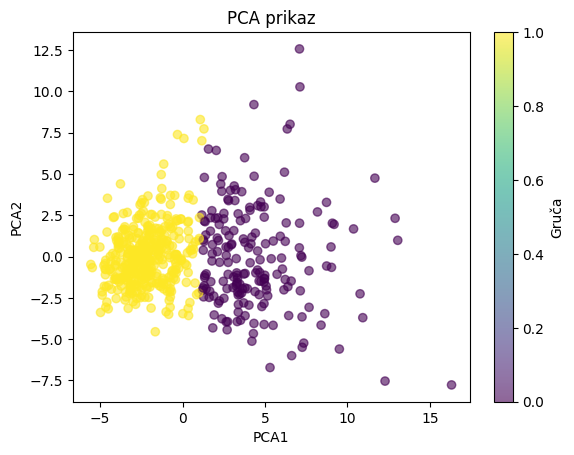

In [22]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

df["PCA1"] = X_pca[:, 0]
df["PCA2"] = X_pca[:, 1]

plt.figure()
plt.scatter(df["PCA1"], df["PCA2"], c=df["cluster"], alpha=0.6)
plt.title("PCA prikaz")
plt.xlabel("PCA1")
plt.ylabel("PCA2")
plt.colorbar(label="Gruča")
plt.show()


S PCA transformacijo smo zmanjšali dimenzionalnost podatkov na dve glavni komponenti, ki zajemata največ variance v podatkih.

Na grafu raztrosa opazimo, da se primerki razdelijo v dve razmeroma jasno ločeni skupini, ki ustrezata gručenju z algoritmom K-means.
Čeprav PCA ne uporablja informacij o diagnozi, se razporeditev podatkov vseeno ujema z osnovno delitvijo med benignimi in malignimi primeri.

To kaže, da razlike med primerki izvirajo iz dominantnih smeri variance v podatkih in da je struktura podatkov dobro izražena že v dveh dimenzijah.

## FastICA transformacija

Naredimo še FastICA transformacijo in na enak način prikažemo kaj smo dobili.


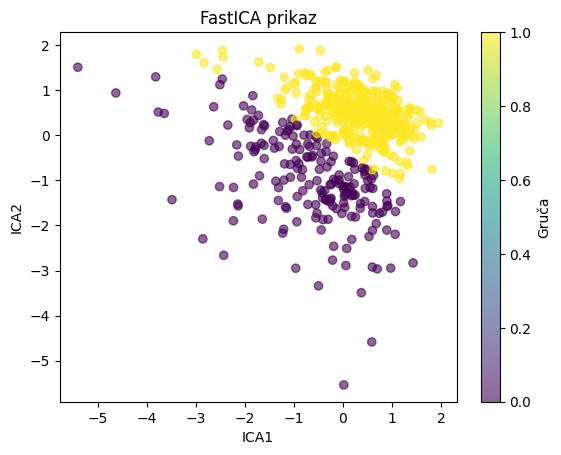

In [23]:
from sklearn.decomposition import FastICA

ica = FastICA(n_components=2, random_state=42, max_iter=1000)
X_ica = ica.fit_transform(X_scaled)

df["ICA1"] = X_ica[:, 0]
df["ICA2"] = X_ica[:, 1]

plt.figure()
plt.scatter(df["ICA1"], df["ICA2"], c=df["cluster"], alpha=0.6)
plt.title("FastICA prikaz")
plt.xlabel("ICA1")
plt.ylabel("ICA2")
plt.colorbar(label="Gruča")
plt.show()


FastICA transformacija išče statistično neodvisne komponente v podatkih, kar omogoča drugačen pogled na njihovo notranjo strukturo.

Tudi pri prikazu z uporabo FastICA opazimo jasno ločevanje med dvema skupinama, čeprav je razporeditev nekoliko drugačna kot pri PCA.
Ena izmed skupin je bolj kompaktna, druga pa bolj razpršena.
To nakazuje večjo heterogenost primerkov, kar je značilno za maligne tumorje, ki se lahko pojavljajo v različnih morfoloških oblikah.
Nasprotno pa so benigni primerki bolj kompaktni, kar kaže na večjo enotnost njihove strukture.

Rezultat potrjuje, da so v podatkih prisotne neodvisne komponente, ki prav tako omogočajo smiselno ločevanje primerkov.

### 7. Dodatna algoritma gručenja (na PCA podatkih)

Nad PCA transformiranimi podatki izvedemo še dva algoritma gručenja in primerjamo rezultate.


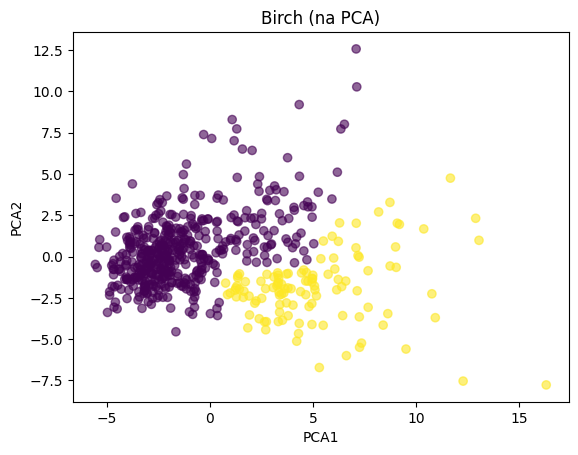

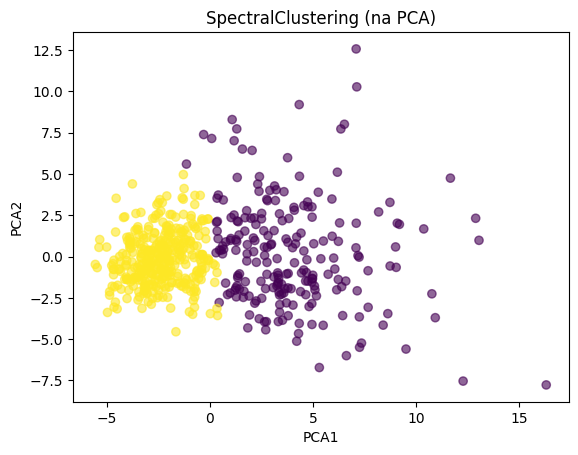

In [24]:
from sklearn.cluster import Birch, SpectralClustering

# Birch
birch = Birch(n_clusters=k_opt)
labels_birch = birch.fit_predict(X_pca)

plt.figure()
plt.scatter(df["PCA1"], df["PCA2"], c=labels_birch, alpha=0.6)
plt.title("Birch (na PCA)")
plt.xlabel("PCA1")
plt.ylabel("PCA2")
plt.show()

# Spectral Clustering
spec = SpectralClustering(n_clusters=k_opt, random_state=42, affinity="nearest_neighbors")
labels_spec = spec.fit_predict(X_pca)

plt.figure()
plt.scatter(df["PCA1"], df["PCA2"], c=labels_spec, alpha=0.6)
plt.title("SpectralClustering (na PCA)")
plt.xlabel("PCA1")
plt.ylabel("PCA2")
plt.show()


Za preverjanje stabilnosti gručenja smo nad PCA transformiranimi podatki uporabili še algoritma Birch in SpectralClustering. Oba algoritma sta zaznala podobno razdelitev primerkov v dve gruči kot K-means, kar kaže, da je zaznana struktura podatkov robustna in neodvisna od izbranega algoritma.

### Razlike med algoritmi se kažejo predvsem v obliki in gostoti gruč, ne pa v osnovni delitvi podatkov.

## 4. Klasifikacija

V tem poglavju izvedemo nadzorovano učenje, kjer je ciljna spremenljivka `diagnosis`
(0 = benigni, 1 = maligni). Podatke razdelimo na učno in testno množico ter
preizkusimo dva modela: logistično regresijo in Random Forest.

Pri nekaterih modelih (npr. logistična regresija) je standardizacija pomembna,
zato jo vključimo v `Pipeline`, da preprečimo podatkovno uhajanje (data leakage).


In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report, roc_auc_score, RocCurveDisplay
)


In [26]:
# X = vse lastnosti, y = ciljna spremenljivka
X = df.drop(columns=["diagnosis"])
y = df["diagnosis"]

# Razdelitev na učno in testno množico (stratify ohrani razmerje razredov)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Učna množica:", X_train.shape, "Testna množica:", X_test.shape)
print("Razmerje razredov v celoti:", y.value_counts(normalize=True))
print("Razmerje razredov v učni množici:", y_train.value_counts(normalize=True))
print("Razmerje razredov v testni množici:", y_test.value_counts(normalize=True))


Učna množica: (455, 35) Testna množica: (114, 35)
Razmerje razredov v celoti: diagnosis
0    0.627417
1    0.372583
Name: proportion, dtype: float64
Razmerje razredov v učni množici: diagnosis
0    0.626374
1    0.373626
Name: proportion, dtype: float64
Razmerje razredov v testni množici: diagnosis
0    0.631579
1    0.368421
Name: proportion, dtype: float64


### 4.2 Logistična regresija (klasifikacija)

Logistična regresija je osnovna in pogosto uporabljena metoda za binarno klasifikacijo.
Model napove verjetnost pripadnosti razredu 1 (maligni), nato pa na podlagi praga
(standardno 0.5) določi razred.

Ker se metoda opira na razdalje v prostoru lastnosti, je standardizacija pomembna,
zato uporabimo `Pipeline` (StandardScaler + LogisticRegression).


In [27]:
log_reg = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=2000, random_state=42))
])

log_reg.fit(X_train, y_train)

y_pred_lr = log_reg.predict(X_test)
y_proba_lr = log_reg.predict_proba(X_test)[:, 1]  # verjetnost razreda 1


In [28]:
print("Logistična regresija - rezultati")
print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr))
print("Recall:", recall_score(y_test, y_pred_lr))
print("F1:", f1_score(y_test, y_pred_lr))
print("ROC AUC:", roc_auc_score(y_test, y_proba_lr))
print("\nClassification report:\n", classification_report(y_test, y_pred_lr))


Logistična regresija - rezultati
Accuracy: 0.956140350877193
Precision: 0.9743589743589743
Recall: 0.9047619047619048
F1: 0.9382716049382716
ROC AUC: 0.9937169312169312

Classification report:
               precision    recall  f1-score   support

           0       0.95      0.99      0.97        72
           1       0.97      0.90      0.94        42

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



Logistična regresija se je izkazala kot zelo učinkovit model za binarno klasifikacijo diagnoze. Model dosega visoko natančnost, kar pomeni, da uspešno razlikuje med benignimi in malignimi tumorji na podlagi morfoloških značilnosti celičnih jeder.

Visoke vrednosti recall so še posebej pomembne v medicinskem kontekstu, saj pomenijo, da model uspešno zazna večino malignih primerov in tako zmanjša tveganje za napačno klasifikacijo nevarnih primerov kot benignih.

ROC AUC vrednost dodatno potrjuje dobro ločljivost razredov, saj model učinkovito razvršča primere glede na verjetnost pripadnosti malignemu razredu.

Rezultati kažejo, da je logistična regresija primerna in zanesljiva metoda za podporo pri diagnostiki raka dojk na podlagi analiziranih značilnosti.

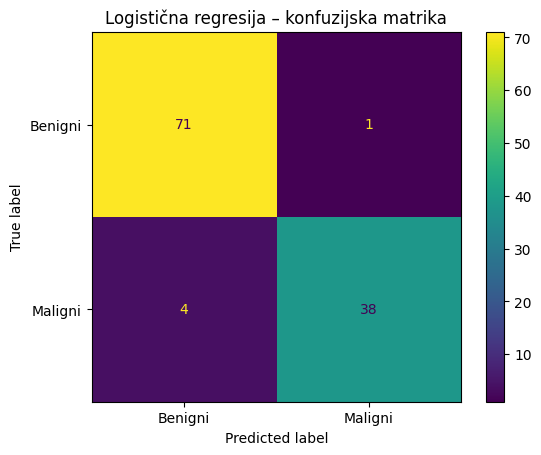

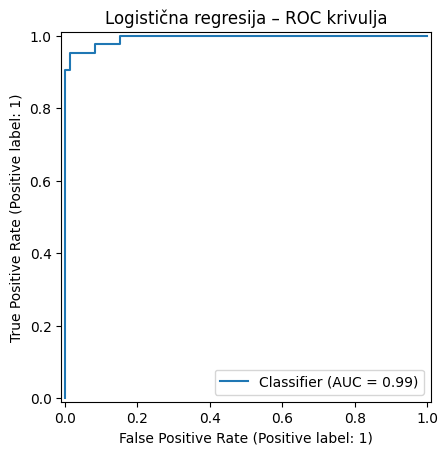

In [29]:
cm_lr = confusion_matrix(y_test, y_pred_lr)

disp = ConfusionMatrixDisplay(confusion_matrix=cm_lr, display_labels=["Benigni", "Maligni"])
disp.plot(values_format="d")
plt.title("Logistična regresija – konfuzijska matrika")
plt.show()

RocCurveDisplay.from_predictions(y_test, y_proba_lr)
plt.title("Logistična regresija – ROC krivulja")
plt.show()

**Interpretacija:**
- Konfuzijska matrika pokaže, koliko primerkov je model pravilno/napačno razvrstil.
- Posebej pomemben je *recall* za razred malignih, saj želimo čim manj lažno negativnih primerov.
- ROC AUC meri sposobnost modela za ločevanje razredov pri različnih pragih.


Konfuzijska matrika prikazuje rezultate klasifikacije. Model je pravilno prepoznal 71 benignih in 38 malignih primerov. Imamo 1 lažno pozitiven rezultat (benigni tumor, ki je bil označen kot maligni) in 4 lažno negativne rezultate (maligni tumorji, ki so bili spregledani kot benigni). Skupna natančnost modela je zelo visoka.

ROC krivulja prikazuje učinkovitost modela pri različnih mejah klasifikacije. Vrednost AUC (površina pod krivuljo) znaša 0,99, kar je izjemen rezultat. To pomeni, da ima model skoraj popolno sposobnost razlikovanja med benignimi in malignimi tumorji. Krivulja, ki se hitro približa zgornjemu levemu kotu, potrjuje visoko zanesljivost logistične regresije v tem primeru.


### 4.3 Random Forest klasifikator

Random Forest je ansambelska metoda, ki združuje več odločitvenih dreves in
običajno doseže zelo dobre rezultate tudi brez standardizacije.
Primerjamo ga z logistično regresijo.


In [30]:
rf = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    class_weight="balanced"
)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
y_proba_rf = rf.predict_proba(X_test)[:, 1]


In [31]:
print("Random Forest - rezultati")
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1:", f1_score(y_test, y_pred_rf))
print("ROC AUC:", roc_auc_score(y_test, y_proba_rf))
print("\nClassification report:\n", classification_report(y_test, y_pred_rf))


Random Forest - rezultati
Accuracy: 0.9736842105263158
Precision: 1.0
Recall: 0.9285714285714286
F1: 0.9629629629629629
ROC AUC: 0.9973544973544972

Classification report:
               precision    recall  f1-score   support

           0       0.96      1.00      0.98        72
           1       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



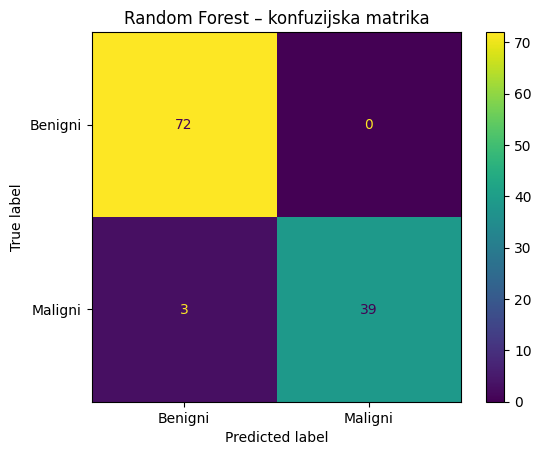

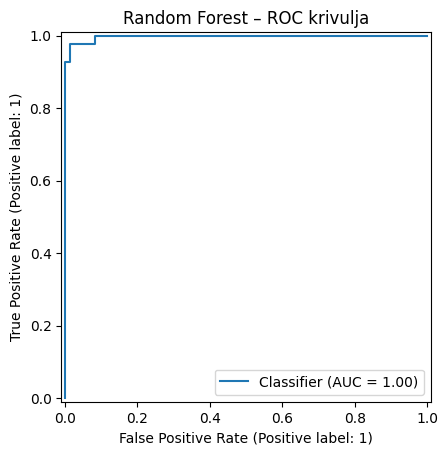

In [32]:
cm_rf = confusion_matrix(y_test, y_pred_rf)

disp = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=["Benigni", "Maligni"])
disp.plot(values_format="d")
plt.title("Random Forest – konfuzijska matrika")
plt.show()

RocCurveDisplay.from_predictions(y_test, y_proba_rf)
plt.title("Random Forest – ROC krivulja")
plt.show()


Konfuzijska matrika za algoritem naključni gozd (Random Forest) kaže izjemne rezultate. Model je pravilno razvrstil vseh 72 benignih primerov, kar pomeni, da nima nobenega lažno pozitivnega rezultata. Pri malignih tumorjih je bil uspešen v 39 primerih, medtem ko je 3 maligne primere napačno označil za benigne (lažno negativni rezultati). Skupna natančnost je višja kot pri logistični regresiji.

ROC krivulja za naključni gozd dosega popolno vrednost AUC = 1,00. To nakazuje, da je model teoretično sposoben popolnega razlikovanja med obema razredoma. Krivulja se skoraj navpično dvigne proti zgornjemu levemu kotu, kar potrjuje, da je ta algoritem izjemno učinkovit pri diagnosticiranju raka dojke na tem naboru podatkov.

### 4.4 Optimizacija parametrov (GridSearchCV)

Za izboljšanje modela izvedemo preprost GridSearch nad logistično regresijo.
S tem preverimo, ali lahko z izbiro regularizacije (C) dosežemo boljše rezultate.


In [33]:
from sklearn.model_selection import GridSearchCV

pipe_lr = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=3000, random_state=42))
])

param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__penalty": ["l2"],
    "model__solver": ["lbfgs"]
}

grid = GridSearchCV(
    pipe_lr,
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Najboljši parametri:", grid.best_params_)
print("Najboljši CV F1:", grid.best_score_)


Najboljši parametri: {'model__C': 0.1, 'model__penalty': 'l2', 'model__solver': 'lbfgs'}
Najboljši CV F1: 0.9597469784079431


In [34]:
best_lr = grid.best_estimator_

y_pred_best = best_lr.predict(X_test)
y_proba_best = best_lr.predict_proba(X_test)[:, 1]

print("Optimizirana logistična regresija - rezultati")
print("Accuracy:", accuracy_score(y_test, y_pred_best))
print("Precision:", precision_score(y_test, y_pred_best))
print("Recall:", recall_score(y_test, y_pred_best))
print("F1:", f1_score(y_test, y_pred_best))
print("ROC AUC:", roc_auc_score(y_test, y_proba_best))


Optimizirana logistična regresija - rezultati
Accuracy: 0.9736842105263158
Precision: 1.0
Recall: 0.9285714285714286
F1: 0.9629629629629629
ROC AUC: 0.9973544973544973


In [35]:
results = pd.DataFrame([
    {
        "Model": "Logistična regresija",
        "Accuracy": accuracy_score(y_test, y_pred_lr),
        "Precision": precision_score(y_test, y_pred_lr),
        "Recall": recall_score(y_test, y_pred_lr),
        "F1": f1_score(y_test, y_pred_lr),
        "ROC_AUC": roc_auc_score(y_test, y_proba_lr)
    },
    {
        "Model": "Random Forest",
        "Accuracy": accuracy_score(y_test, y_pred_rf),
        "Precision": precision_score(y_test, y_pred_rf),
        "Recall": recall_score(y_test, y_pred_rf),
        "F1": f1_score(y_test, y_pred_rf),
        "ROC_AUC": roc_auc_score(y_test, y_proba_rf)
    },
    {
        "Model": "Optimizirana LR (GridSearch)",
        "Accuracy": accuracy_score(y_test, y_pred_best),
        "Precision": precision_score(y_test, y_pred_best),
        "Recall": recall_score(y_test, y_pred_best),
        "F1": f1_score(y_test, y_pred_best),
        "ROC_AUC": roc_auc_score(y_test, y_proba_best)
    }
])

results


,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistična regresija,0.956140,0.974359,0.904762,0.938272,0.993717
1,Random Forest,0.973684,1.000000,0.928571,0.962963,0.997354
2,Optimizirana LR (GridSearch),0.973684,1.000000,0.928571,0.962963,0.997354


**Zaključek:**
Primerjava kaže, kateri model najbolje loči med benignimi in malignimi primerki.
Pri tem je pomembno, da poleg accuracy upoštevamo tudi recall in F1, saj je pri
zdravstvenih podatkih posebej kritično zmanjšati lažno negativne napovedi.


####Visoka uspešnost modelov je posledica močne korelacije med morfološkimi lastnostmi in diagnozo, kar potrjuje tudi predhodna korelacijska analiza.

#5. Regresija – napoved kontinuirane vrednosti

Namen regresije je napovedati kontinuirano numerično lastnost na podlagi ostalih atributov v podatkovni zbirki.
V tem primeru bomo napovedovali povprečno površino jedra (area_mean), saj je ta lastnost močno povezana z drugimi morfološkimi značilnostmi tumorja in ima jasen biološki pomen.

In [36]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Ciljna spremenljivka
y_reg = df["area_mean"]

# Vhodne lastnosti (brez targeta in brez diagnosis)
X_reg = df.drop(columns=["area_mean", "diagnosis", "cluster"], errors="ignore")

# Razdelitev na učno in testno množico
X_train, X_test, y_train, y_test = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=42
)

# Standardizacija
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train.shape, X_test.shape


((455, 33), (114, 33))

Podatke standardiziramo, saj imajo posamezne lastnosti zelo različne skale, kar vpliva na delovanje regresijskih modelov.

##Linearna regresija

In [37]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

lr = LinearRegression()
lr.fit(X_train_scaled, y_train)

y_pred_lr = lr.predict(X_test_scaled)

print("Linearna regresija:")
print("R²:", r2_score(y_test, y_pred_lr))
print("MAE:", mean_absolute_error(y_test, y_pred_lr))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_lr)))


Linearna regresija:
R²: 1.0
MAE: 6.237817280251826e-13
RMSE: 8.669745256552036e-13


##Ridge regresija (regularizacija)

In [38]:
from sklearn.linear_model import Ridge

ridge = Ridge(alpha=1.0)
ridge.fit(X_train_scaled, y_train)

y_pred_ridge = ridge.predict(X_test_scaled)

print("Ridge regresija:")
print("R²:", r2_score(y_test, y_pred_ridge))
print("MAE:", mean_absolute_error(y_test, y_pred_ridge))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_ridge)))


Ridge regresija:
R²: 0.9957822845521364
MAE: 14.332595860493578
RMSE: 22.05336521650223


##Random Forest regresija

In [39]:
from sklearn.ensemble import RandomForestRegressor

rf_reg = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

rf_reg.fit(X_train, y_train)  # RF ne potrebuje standardizacije
y_pred_rf = rf_reg.predict(X_test)

print("Random Forest regresija:")
print("R²:", r2_score(y_test, y_pred_rf))
print("MAE:", mean_absolute_error(y_test, y_pred_rf))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_rf)))


Random Forest regresija:
R²: 0.9982672219869257
MAE: 7.182403508771888
RMSE: 14.1353867628095


##Vizualna primerjava: dejanske vs. napovedane vrednosti

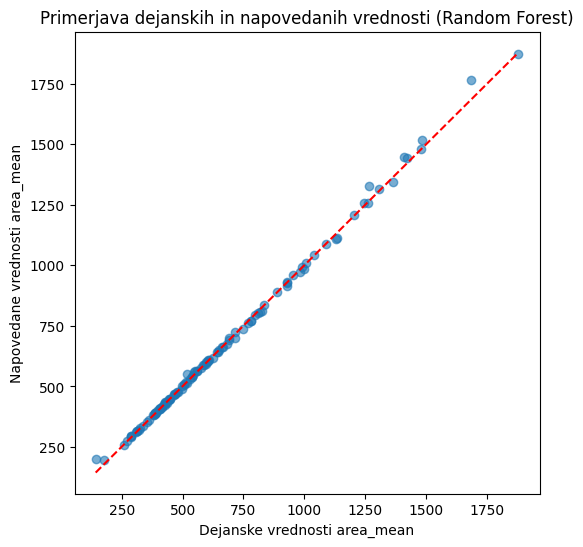

In [40]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred_rf, alpha=0.6)
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         color="red", linestyle="--")

plt.xlabel("Dejanske vrednosti area_mean")
plt.ylabel("Napovedane vrednosti area_mean")
plt.title("Primerjava dejanskih in napovedanih vrednosti (Random Forest)")
plt.show()


##Primerjava regresijskih modelov

In [41]:
import pandas as pd

results_reg = pd.DataFrame({
    "Model": ["Linearna regresija", "Ridge regresija", "Random Forest"],
    "R2": [
        r2_score(y_test, y_pred_lr),
        r2_score(y_test, y_pred_ridge),
        r2_score(y_test, y_pred_rf)
    ],
    "MAE": [
        mean_absolute_error(y_test, y_pred_lr),
        mean_absolute_error(y_test, y_pred_ridge),
        mean_absolute_error(y_test, y_pred_rf)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, y_pred_lr)),
        np.sqrt(mean_squared_error(y_test, y_pred_ridge)),
        np.sqrt(mean_squared_error(y_test, y_pred_rf))
    ]
})

results_reg


,Model,R2,MAE,RMSE
0,Linearna regresija,1.000000,6.237817e-13,8.669745e-13
1,Ridge regresija,0.995782,1.433260e+01,2.205337e+01
2,Random Forest,0.998267,7.182404e+00,1.413539e+01


V prejšnji regresijski analizi smo kot ciljno spremenljivko uporabili area_mean, pri čemer so modeli dosegli izjemno visoko napovedno natančnost. Tak rezultat je pričakovan, saj je area_mean matematično in strukturno zelo močno povezana z večino ostalih lastnosti v podatkovni množici (npr. radius_mean, perimeter_mean, area_worst), kar vodi do skoraj determinističnega odnosa.

Z namenom bolj realistične ocene regresijskih modelov in njihove sposobnosti posploševanja zato v nadaljevanju izvedemo dodatno regresijsko analizo, kjer za ciljno spremenljivko izberemo lastnost, ki ni neposredno matematično izpeljana iz ostalih. Na ta način dobimo bolj smiselne in interpretativno uporabne rezultate ter realnejši vpogled v delovanje regresijskih metod na manj trivialnih odnosih med spremenljivkami.

In [42]:
features_reg = [
    "texture_mean",
    "smoothness_mean",
    "compactness_mean",
    "concavity_mean",
    "symmetry_mean"
]


In [43]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df[features_reg]
y = df["fractal_dimension_mean"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [44]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

lr = LinearRegression()
lr.fit(X_train_scaled, y_train)

y_pred = lr.predict(X_test_scaled)

print("Linearna regresija:")
print("R2:", r2_score(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))


Linearna regresija:
R2: 0.556821789353104
MAE: 0.0034782957694692858
RMSE: 0.00427967980153878


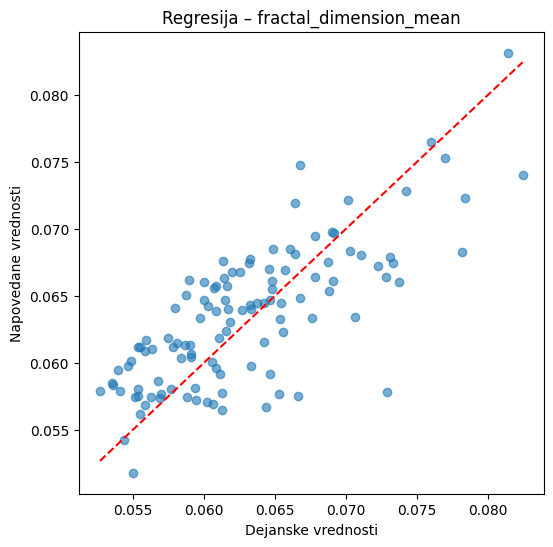

In [45]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))
plt.scatter(y_test, y_pred, alpha=0.6)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)
plt.xlabel("Dejanske vrednosti")
plt.ylabel("Napovedane vrednosti")
plt.title("Regresija – fractal_dimension_mean")
plt.show()


Pri prvem regresijskem primeru smo dobili skoraj popolno napovedno moč, kar je posledica močne matematične povezanosti med ciljno spremenljivko in vhodnimi lastnostmi.

Zato smo v nadaljevanju izvedli še regresijo nad klinično manj neposredno povezano lastnostjo (fractal_dimension_mean), kjer so rezultati realnejši. Model kljub temu uspe pojasniti več kot polovico variabilnosti ciljne spremenljivke, kar kaže na obstoj smiselnega, a ne trivialnega odnosa med lastnostmi.

Rezultati linearne regresije kažejo zmeren napovedni uspeh (R² ≈ 0.56), kar pomeni, da model pojasni približno 56 % variabilnosti ciljne spremenljivke. Vrednosti MAE in RMSE so relativno nizke, kar nakazuje, da napovedi niso močno obremenjene z velikimi napakami, vendar hkrati potrjujejo, da popolna napoved pri takšnih podatkih ni mogoča.

Vizualni prikaz primerjave dejanskih in napovedanih vrednosti dodatno pokaže, da so napovedi razpršene okoli idealne premice, kar je pričakovano pri bioloških podatkih, kjer pomembno vlogo igrajo tudi drugi, v podatkih ne zajeti dejavniki. Takšni rezultati so realistični in bolj reprezentativni za praktično uporabo regresijskih modelov.